# EDA: комментарии инвесторов на Smart-Lab

Было собрано 986 188 комментариев с форума Smart-Lab по 209 акциям Московской биржи за пять лет - с 8 ноября 2021 по 8 ноября 2026 года. 

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_colwidth', 100)

In [2]:
df = pd.read_csv(
    'data/processed/smartlab_comments_5y.csv',
    encoding='utf-8-sig',
    dtype={'source_id': 'string', 'parent_id': 'string', 'author_id': 'string'},
    keep_default_na=False,
    na_values=[''],
)

## Как выглядят данные?

In [3]:
print(df.shape)
df.sample(5, random_state=0)[['ticker', 'published_at_msk', 'author_id', 'parent_id', 'score', 'text']]

(986188, 14)


,ticker,published_at_msk,author_id,parent_id,score,text
932821,VTBR,2025-12-13T06:59:03+03:00,StrashnyyModul,<NA>,0,"Совокупность всех этих негативных факторов (геополитических, макроэкономических, внутрикорпорати..."
847673,UGLD,2024-08-02T16:13:22+03:00,Tayson1977,<NA>,0,2 519 $ хорошая тенденция у нас только в обратную сторону
826960,TATN,2024-03-28T09:22:21+03:00,Markitant,16711792,5,"Metzger, Хомяк с биржи, цитата «Это не компания роста, а дивидендная история» Погуглил наудачу: ..."
651833,SBER,2024-09-11T23:12:43+03:00,Zagreus86,17279782,0,"Сейчас я вам набрехаю что, заблуждаетесь."
556016,SBER,2022-11-08T12:33:26+03:00,vaskes,14997171,0,"Gorik, сегодня розд наблюдается. В индексе минимумы и максимумы пока растут. Закроемся я думаю в..."


Одна строка - это один комментарий: на странице какой акции он написан, когда, кем, в ответ на какое сообщение (`parent_id`), сколько оценок набрал (`score`) и сам текст. Остальные столбцы служебные: ID, ссылка, время скачивания.

In [4]:
df.dtypes

source                  str
ticker                  str
record_type             str
source_id            string
parent_id            string
published_at_utc        str
published_at_msk        str
author_id            string
author_name             str
text                    str
score                 int64
comments_count      float64
url                     str
collected_at_utc        str
dtype: object

Можем заметить проблему - даты прочитались как строки. Переведём даты в формат `datetime`. Если какая-то дата окажется битой, она превратится в `NaT`.

In [5]:
df['published_at_utc'] = pd.to_datetime(df['published_at_utc'], utc=True, errors='coerce')
df['published_at_msk'] = pd.to_datetime(df['published_at_msk'], utc=True, errors='coerce').dt.tz_convert('Europe/Moscow')

In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
source,986188,1,smart-lab,986188,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ticker,986188,209,SBER,211494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
record_type,986188,1,forum_comment,986188,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_id,986188,986188,13189149,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parent_id,502283,405360,18359999,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
published_at_utc,986188,NaN,NaN,NaN,2024-05-18 09:17:19.636399+00:00,2021-11-08 00:04:56+00:00,2023-03-28 19:32:45.750000+00:00,2024-05-20 09:10:40.500000+00:00,2025-07-30 09:05:12.500000+00:00,2026-11-08 08:47:26+00:00,NaN
published_at_msk,986188,NaN,NaN,NaN,2024-05-18 12:17:19.636399+03:00,2021-11-08 03:04:56+03:00,2023-03-28 22:32:45.750000+03:00,2024-05-20 12:10:40.500000+03:00,2025-07-30 12:05:12.500000+03:00,2026-11-08 11:47:26+03:00,NaN
author_id,986188,12578,disclosure,46312,NaN,NaN,NaN,NaN,NaN,NaN,NaN
author_name,986188,11389,Раскрывальщик,46312,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,986188,942821,"""РОСИНТЕР РЕСТОРАНТС ХОЛДИНГ"" Совершение подконтрольной эмитенту организацией существенной сделк...",253,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Что видно из `describe`:

* `source` и `record_type` везде одинаковые - всё это комментарии Smart-Lab, как признаки они бесполезны;
* у `comments_count` нет ни одного значения, у `parent_id` заполнена примерно половина строк - есть пропуски;
* имён авторов меньше, чем ID (11 389 против 12 578), поэтому автора определяем по `author_id`;
* уникальных текстов меньше, чем строк, - значит, есть повторы;
* у `score` медиана и оба квартиля равны нулю: большинство комментариев никто не оценивает.

## Очистка данных

### Шаг 1. Пропуски

In [7]:
missing = df.isna().sum()

pd.DataFrame({
    'пропусков': missing,
    'доля, %': (missing / len(df) * 100).round(2),
})[missing > 0]

,пропусков,"доля, %"
parent_id,483905,49.07
comments_count,986188,100.00


Пропуски только в двух столбцах. `comments_count` пустой целиком: для комментариев форума сайт это число не отдаёт, так что столбец просто удалим.

`parent_id` пуст у 49% строк. Можем предположить, что это сообщения, которые ни на что не отвечают. Сделаем проверку - если гипотеза верна, у ответов родительское сообщение должно находиться в нашем же корпусе.

In [8]:
replies = df.loc[df['parent_id'].notna(), ['ticker', 'parent_id']]
all_keys = pd.MultiIndex.from_frame(df[['ticker', 'source_id']])
print('Ответов, у которых нашёлся родитель:', f'{pd.MultiIndex.from_frame(replies).isin(all_keys).mean():.0%}')

Ответов, у которых нашёлся родитель: 91%


Родитель нашёлся у 91% ответов (остальные, вероятно, отвечают на сообщения старше начала выгрузки). Значит, пустой `parent_id` - это не потерянные данные, а «не ответ». Заполнять его нечем, поэтому заменим на флаг `is_reply`.

### Шаг 2. Ошибочные значения

In [9]:
pd.Series({
    'битая дата': df['published_at_utc'].isna().sum(),
    'дата вне периода': (~df['published_at_utc'].between('2021-11-08', '2026-11-09', inclusive='left')).sum(),
    'пустой текст': df['text'].str.strip().eq('').sum(),
    'повтор ID внутри тикера': df.duplicated(['ticker', 'source_id']).sum(),
})

битая дата                 0
дата вне периода           0
пустой текст               0
повтор ID внутри тикера    0
dtype: int64

Формально ошибок нет. Однако, при сборе из ответов мы специально убирали процитированный текст родительского сообщения, чтобы чужие слова не попадали в текст ответа. 
Если человек ответил только цитатой или картинкой, от текста осталось лишь обращение вроде «Марэк,».

In [10]:
text = df['text'].str.strip()
only_name = text.str.fullmatch(r'[\w .\-]{1,40},')
one_letter = text.str.fullmatch(r'[A-Za-zА-Яа-яЁё]')
bad_text = only_name | one_letter

print('Только обращение:', only_name.sum())
print('Одна буква:', one_letter.sum())
df.loc[bad_text, ['ticker', 'text']].sample(5, random_state=0)

Только обращение: 4657
Одна буква: 55


,ticker,text
754531,SMLT,"Gibson,"
749252,SMLT,"petra66,"
925156,VTBR,"Остап1978,"
684910,SBER,"Александр Ядрихинский,"
494044,RTKM,"добрый волчонок,"


Таких текстов 4 712. Получаем тексты, в которых значение есть, но смысла в нём нет. Ошибку превращаем в пропуск, а строку не удаляем, так как сам факт ответа всё равно говорит об активности обсуждения.

In [11]:
df.loc[bad_text, 'text'] = np.nan

### Шаг 3. Дубликаты

ID у всех записей разные, но одинаковые тексты встречаются. Сразу отметим авто-репосты: так Smart-Lab помечает анонсы постов из блогов, которые автоматически публикуются в форуме.

In [12]:
df = df.sort_values('published_at_utc')
df['text_norm'] = df['text'].str.strip().str.casefold()
df['is_autorepost'] = df['text'].str.contains('Авто-репост', na=False)

repeat = df['text_norm'].notna() & df.duplicated('text_norm')
print('Повторов текста:', repeat.sum())
print('Из них авто-репостов:', f"{df.loc[repeat, 'is_autorepost'].mean():.0%}")
print('Авто-репостов во всём корпусе:', f"{df['is_autorepost'].mean():.0%}")

Повторов текста: 40796
Из них авто-репостов: 86%
Авто-репостов во всём корпусе: 21%


Почти все повторы - авто-репосты, а всего их пятая часть корпуса. Анонсы обрезаны, поэтому, например, разные «Решения совета директоров» одной компании выглядят одинаково. Чтобы понять, что удалять, разложим повторы по происхождению.

In [13]:
gap = df.groupby(['ticker', 'author_id', 'text_norm'])['published_at_utc'].diff()

df['repeat_type'] = np.select(
    [~repeat,
     gap <= pd.Timedelta('10min'),
     df.duplicated(['author_id', 'text_norm', 'published_at_utc']),
     df.duplicated(['author_id', 'text_norm'])],
    ['-', 'отправил дважды', 'тот же пост в другом форуме', 'тот же автор позже'],
    default='другой автор',
)
df.loc[repeat, 'repeat_type'].value_counts()

repeat_type
тот же автор позже             21291
тот же пост в другом форуме    15364
отправил дважды                 2407
другой автор                    1734
Name: count, dtype: int64

* **Отправил дважды** (2 407) - тот же текст в тот же форум с разницей до 10 минут. Это настоящие дубли, они раздувают активность, их лучше убрать.
* **Тот же пост в другом форуме** (15 364) - одна публикация сразу на страницах нескольких акций. Для каждой акции это честное упоминание, оставляем, но помечаем `is_crosspost`.
* **Тот же автор позже** и **другой автор** - разные публикации с одинаковым текстом (анонсы, короткие реплики вроде «Почему падаем?»).

In [14]:
df = df[df['repeat_type'] != 'отправил дважды'].copy()
df['is_crosspost'] = df['text_norm'].notna() & df.duplicated(['author_id', 'text_norm', 'published_at_utc'], keep=False)

df['is_reply'] = df['parent_id'].notna()
df = df.drop(columns='comments_count')
print('Осталось строк:', len(df))

Осталось строк: 983781


Заодно обработали пропуски из шага 1: добавили `is_reply` и удалили пустой столбец. Пропуски в тексте (те самые 4 712) оставляем - у текста нет «медианы», которой можно было бы заполнить; в текстовые признаки эти строки просто не попадут.

### Шаг 4. Выбросы

Добавим длину текста в символах и словах и посмотрим на boxplot.

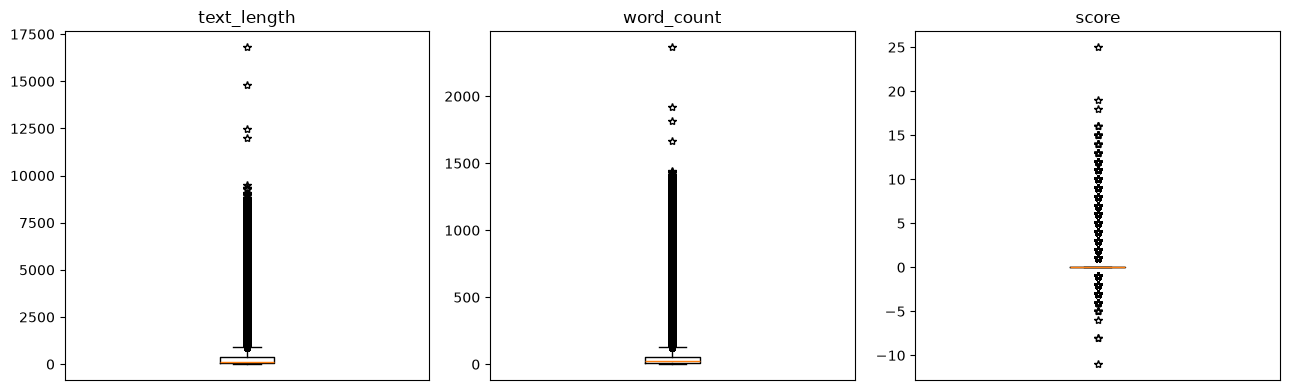

,text_length,word_count,score
count,979069.0,979069.0,983781.0
mean,327.6,48.8,0.3
std,493.5,74.2,0.8
min,1.0,1.0,-11.0
25%,62.0,10.0,0.0
50%,136.0,22.0,0.0
75%,392.0,57.0,0.0
max,16810.0,2366.0,25.0


In [15]:
df['text_length'] = df['text'].str.strip().str.len()
df['word_count'] = df['text'].str.count(r'\S+')
numeric = ['text_length', 'word_count', 'score']

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, numeric):
    ax.boxplot(df[col].dropna(), sym='*')
    ax.set_title(col)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

df[numeric].describe().round(1)

In [16]:
q1, q3 = df[numeric].quantile(.25), df[numeric].quantile(.75)
outside = df[numeric].gt(q3 + 1.5 * (q3 - q1)) | df[numeric].lt(q1 - 1.5 * (q3 - q1))
print('Доля «выбросов» по boxplot, %:', (outside.mean() * 100).round(1).to_dict())
print('Авто-репостов среди длинных:', f"{df.loc[outside['text_length'], 'is_autorepost'].mean():.0%}")

df.nlargest(3, 'text_length')[['ticker', 'is_autorepost', 'text_length', 'text']]

Доля «выбросов» по boxplot, %: {'text_length': 11.3, 'word_count': 11.4, 'score': 23.4}
Авто-репостов среди длинных: 70%


,ticker,is_autorepost,text_length,text
572352,SBER,True,16810.0,"Герман Греф положил вкладчиков ""Сбера"" в карман Самый крупный розничный банк России всё больше с..."
343946,MGNT,True,14779.0,Магнит - дивиденды по результатам девяти месяцев 2021 года — рекомендация совета директоров Сове...
732359,SMLT,True,12456.0,❗️Акции Самолёт: взлетаем или уже налетались? Обзор компании 🏗️Самолёт – один из крупнейших росс...


Длина сильно скошена: медиана 136 символов, среднее 328. Boxplot записывает в «выбросы» 11% текстов, но 70% из них - авто-репосты, а самые длинные тексты — обычные статьи. То есть это не аномалии, а другой тип сообщений. У `score` межквартильный размах нулевой, и выбросом считается любая оценка, кроме нуля.

## Распределения признаков

### Какие акции обсуждают

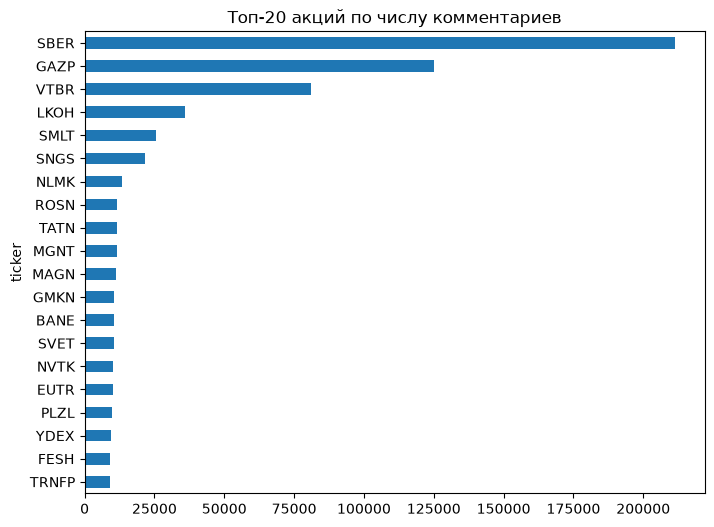

Доля трёх самых обсуждаемых акций: 42%
Акций, где меньше 1000 комментариев: 101
Акций, где больше половины — авто-репосты: 104


In [17]:
ticker_counts = df['ticker'].value_counts()
ticker_counts.head(20).sort_values().plot.barh(figsize=(8, 6), title='Топ-20 акций по числу комментариев')
plt.show()

autorepost_share = df.groupby('ticker')['is_autorepost'].mean()
print('Доля трёх самых обсуждаемых акций:', f'{ticker_counts.head(3).sum() / len(df):.0%}')
print('Акций, где меньше 1000 комментариев:', (ticker_counts < 1000).sum())
print('Акций, где больше половины — авто-репосты:', (autorepost_share > .5).sum())

Обсуждения очень неравномерны: SBER, GAZP и VTBR дают 42% всех комментариев, а у половины акций меньше тысячи сообщений за пять лет. У 104 акций больше половины сообщений - авто-репосты, то есть по редким бумагам на форуме в основном анонсы, а не мнения людей. Можем сделать вывод, что активность по акции лучше сравнивать с её же прошлым уровнем, а не с другими акциями.

### Когда пишут

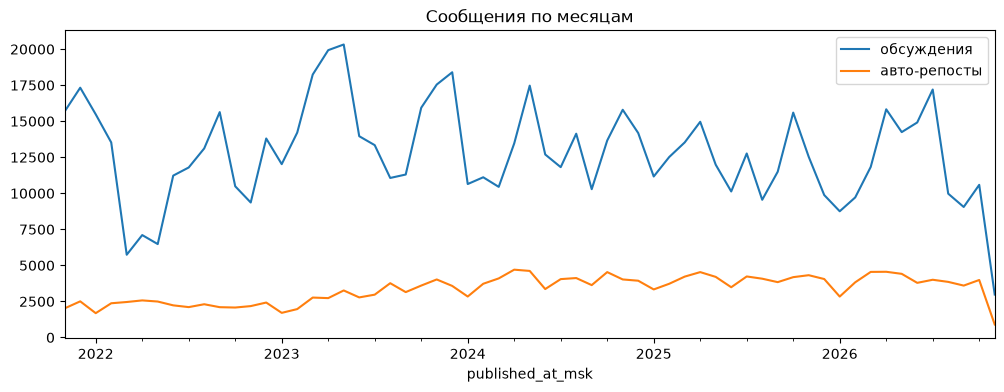

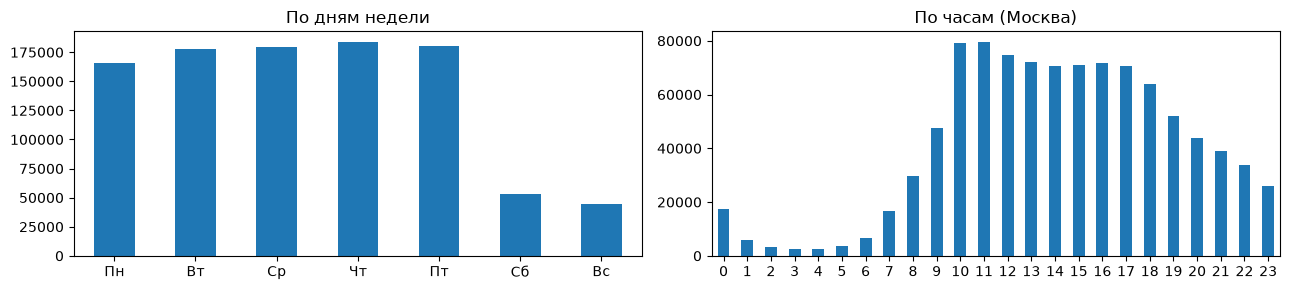

In [18]:
monthly = df.set_index('published_at_msk').groupby('is_autorepost').resample('MS').size().unstack(0)
monthly.columns = ['обсуждения', 'авто-репосты']
monthly.plot(figsize=(12, 4), title='Сообщения по месяцам')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3))
weekdays = df['published_at_msk'].dt.day_of_week.value_counts().sort_index()
weekdays.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
weekdays.plot.bar(ax=axes[0], rot=0, title='По дням недели', xlabel='')
df['published_at_msk'].dt.hour.value_counts().sort_index().plot.bar(ax=axes[1], rot=0, title='По часам (Москва)', xlabel='')
plt.tight_layout()
plt.show()

Число обсуждений колеблется без явного тренда, а авто-репостов за пять лет стало примерно вдвое больше. Поэтому активность будем считать отдельно по двум группам, иначе рост анонсов можно принять за рост интереса инвесторов.

Пишут в основном по будням и в торговые часы, пик - с 10 до 12 утра. Сообщения, написанные вечером и в выходные, будем относить к следующей торговой сессии.

### Сколько дней с сообщениями

Посмотрим, в какой доле дней по акции вообще что-то пишут.

In [19]:
df['day'] = df['published_at_msk'].dt.normalize()
n_days = (df['day'].max() - df['day'].min()).days + 1

def active_days(frame):
    return frame.groupby('ticker')['day'].nunique().reindex(ticker_counts.index, fill_value=0) / n_days

active = active_days(df)
active_discussion = active_days(df[~df['is_autorepost']])
print('Пар «акция × день» хотя бы с одним сообщением:', f'{active.mean():.0%}')
print('Акций, где сообщения есть хотя бы в половине дней:', (active >= .5).sum())
print('То же без авто-репостов:', (active_discussion >= .5).sum())

Пар «акция × день» хотя бы с одним сообщением: 32%
Акций, где сообщения есть хотя бы в половине дней: 48
То же без авто-репостов: 20


Таблица, скорее всего, получится очень разреженной: сообщения есть лишь в трети пар «акция × день», а регулярно (хотя бы через день) живые обсуждения идут всего по 20 акциям. День без сообщений - это не пропуск, а нулевая активность. Основные эксперименты логично ставить на этих 20–50 бумагах.

### Кто пишет

In [20]:
authors = df.groupby('author_id').agg(
    comments=('source_id', 'size'),
    autorepost_share=('is_autorepost', 'mean'),
    tickers=('ticker', 'nunique'),
).sort_values('comments', ascending=False)

print('Доля 100 самых активных авторов:', f"{authors['comments'].head(100).sum() / len(df):.0%}")
authors.head(10).round(2)

Доля 100 самых активных авторов: 49%


,comments,autorepost_share,tickers
author_id,,,
disclosure,44030,1.00,207
Nordstream,26699,0.99,200
DmitriyPervyy,16105,0.00,40
Buterbrod2018,11827,1.00,146
Marek,11420,0.20,207
editor2,10516,0.99,153
Avant,10404,0.00,80
hoster,10029,0.00,65
SergeyHoroshavin,9756,0.00,106


Сто самых активных авторов пишут почти половину сообщений, а четверо из первой десятки (`disclosure`, `Nordstream`, `Buterbrod2018`, `editor2`) публикуют только авто-репосты сразу в 150–200 форумов. Так что число сообщений не равно числу мнений, можем сделать вывод, что в признаки можно добавить ещё и число уникальных авторов.

## Взаимосвязи

Авто-репосты всплывали в каждом разделе. Сравним их с обычными обсуждениями.

In [21]:
df.groupby('is_autorepost').agg(
    comments=('source_id', 'size'),
    median_length=('text_length', 'median'),
    reply_share=('is_reply', 'mean'),
    crosspost_share=('is_crosspost', 'mean'),
    zero_score_share=('score', lambda s: s.eq(0).mean()),
).round(3)

,comments,median_length,reply_share,crosspost_share,zero_score_share
is_autorepost,,,,,
False,779859,97.0,0.644,0.001,0.739
True,203922,661.0,0.002,0.147,0.868


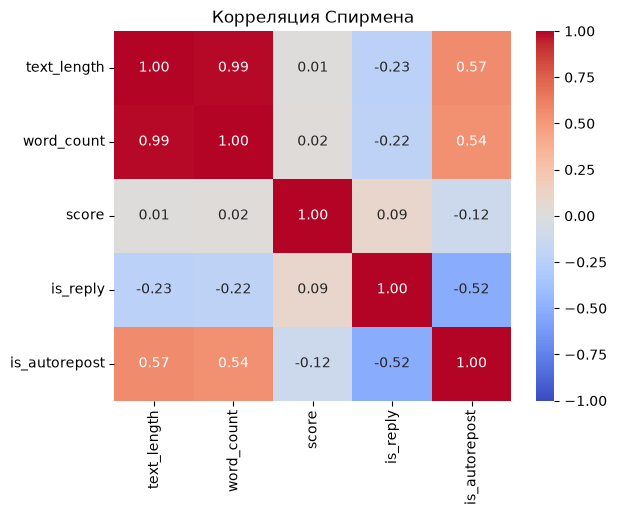

In [22]:
corr = df[numeric + ['is_reply', 'is_autorepost']].astype(float).corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Корреляция Спирмена')
plt.show()

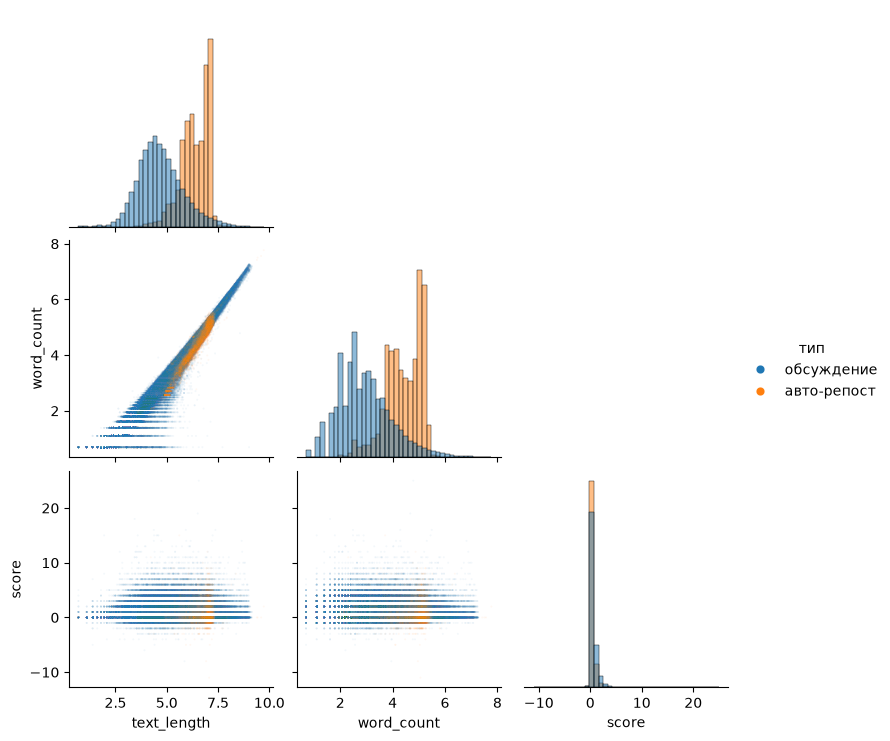

In [23]:
pair = df.loc[df['text'].notna(), numeric].copy()
pair[['text_length', 'word_count']] = np.log1p(pair[['text_length', 'word_count']])
pair['тип'] = np.where(df.loc[pair.index, 'is_autorepost'], 'авто-репост', 'обсуждение')

grid = sns.pairplot(pair, hue='тип', corner=True, diag_kind='hist',
                    plot_kws={'s': 2, 'alpha': .05, 'rasterized': True},
                    diag_kws={'bins': 40, 'stat': 'density', 'common_norm': False})
for handle in grid.legend.legend_handles:
    handle.set_alpha(1)
    handle.set_markersize(6)
plt.show()

Это действительно два разных типа данных. Авто-репосты длинные (медиана 661 символ против 97), почти никогда не бывают ответами и часто дублируются в нескольких форумах. На pairplot их распределения длины лишь слегка пересекаются с обсуждениями - скошенность длины, которую мы видели на boxplot, объясняется именно смесью двух групп.

## Выводы

1) Формальных ошибок в данных нет. Нашли 4 712 текстов, где осталось только обращение к собеседнику, заменили на пропуски, строки сохранили.

2) Пропуски есть в двух столбцах: пустой `comments_count` удалили, пропуск в `parent_id` означает «не ответ» и превратился во флаг `is_reply`.

3) Удалили 2 407 случайных повторных отправок. Копии одного поста в разных форумах оставили и пометили, чтобы учесть их при разбиении на train и test.

4) Пятая часть корпуса - авто-репосты: анонсы блогов и раскрытия компаний. На них приходятся почти все повторы и большая часть «выбросов» по длине. Признаки будем строить отдельно для живых обсуждений и для авто-репостов и проверим, что полезнее.

5) Выбросы по boxplot не удаляем: это правдоподобные длинные тексты. Длину будем логарифмировать.

6) Данные сильно разрежены по дням: регулярно обсуждаются только 20–50 акций. Активность будем сравнивать с прошлым уровнем самой акции и учитывать число уникальных авторов.

7) `score` в модель не берём — оценки накапливаются после публикации. Признаки за день считаем только по сообщениям, написанным до момента прогноза.